# 19 — Las familias de enfermedad: no solo IRA

## La pregunta y por qué importa

A Manizales no le dan solo problemas respiratorios. Una ciudad de ladera, con lluvia fuerte, sismos, violencia y
una red de salud que cambia de asegurador dominante, tiene varias enfermedades con calendarios y gatillos propios.
Si el modelo de triage solo conoce la IRA, tiene una sola señal para explicar picos que vienen de causas distintas.

Este cuaderno arma un repertorio de **seis familias de enfermedad** de la ciudad y responde cuatro preguntas:
cuándo sube cada una, si el clima las mueve, si el hospital las ve en su triage y, dentro de los episodios
concretos (epidemias, el paro nacional de 2021, los desastres), si hay efectos que un promedio de años diluye.

## Las seis familias

Se arman con las series semanales de Manizales del sistema de vigilancia en salud pública (SIVIGILA).

| Familia | Series | ¿Hay dato de 2026 al predecir? |
|---|---|---|
| **Respiratoria** | IRA total, IRA 0-4, IRA 60+, hospitalizaciones por IRAG | sí (tablero del INS, ~1 semana) |
| **Digestiva** | EDA total, EDA 0-4 | **no**: solo microdatos, con ~8 meses de retraso |
| **Violencias y agresiones** | violencia de género e intrafamiliar (875), agresiones por animales (300) | sí (tablero del INS) |
| **Salud mental e intoxicaciones** | intento de suicidio (356), intoxicaciones (365) | sí |
| **Materno-perinatal** | morbilidad materna extrema (549) | sí |
| **Inmunoprevenibles** | varicela (831) | sí |

Cada serie se convierte en una anomalía *operativa*: el logaritmo contra la media de las 52 semanas previas, que
es lo único que se sabría esa semana. Cada familia es el promedio de sus series estandarizadas, con la
estandarización ajustada solo con datos hasta 2024. La definición vive en el módulo compartido de índices, que usa
también el reentrenamiento, de modo que el modelo recibe exactamente lo que aquí se exploró.

**Límite de partida.** La familia digestiva no tiene datos de 2026: el INS publica los microdatos de la EDA con
unos ocho meses de retraso y el tablero semanal no la incluye. Sirve para explicar y medir, pero no para operar, y
todo este cuaderno se limita a 2012-2024.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, statsmodels.api as sm
from scipy.stats import poisson
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")
from matplotlib import pyplot as plt
import indices as ix
import desenlace as dz
from desenlace import desenlace_semanal
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FIN = ix.REF_FIN
FAM_C = ix.familias_enfermedad().loc["2012":FIN]                 # con la COVID, para los episodios
FAM = ix.familias_enfermedad().loc[:FIN]
FAM[(FAM.index >= "2020-03-15") & (FAM.index <= "2021-12-31")] = np.nan      # la COVID desordena la notificacion
S = ix.series_sivigila().loc["2012":FIN]
print("Casos o consultas totales 2012-2024 por serie:"); S.sum().astype(int).sort_values(ascending=False)

Casos o consultas totales 2012-2024 por serie:


995_consultas_ira_total             839229
998_casos_eda_total                 340101
995_consultas_ira_0_4               174279
995_consultas_ira_60_mas            132695
998_casos_eda_0_4                    42250
995_hospitalizaciones_irag_total     30218
300_casos                            13367
875_casos                            11103
365_casos                             6862
356_casos                             5370
831_casos                             5270
549_casos                             3034
dtype: int32

---
# 1. La estación de cada familia

Para cada serie se resta la media de su propio año (la forma del año, sin el nivel de cada año) y se promedia por
mes sobre 2015-2024, sin las semanas de la COVID (2020-03-15 a 2021-12-31), que desordenaron la notificación.

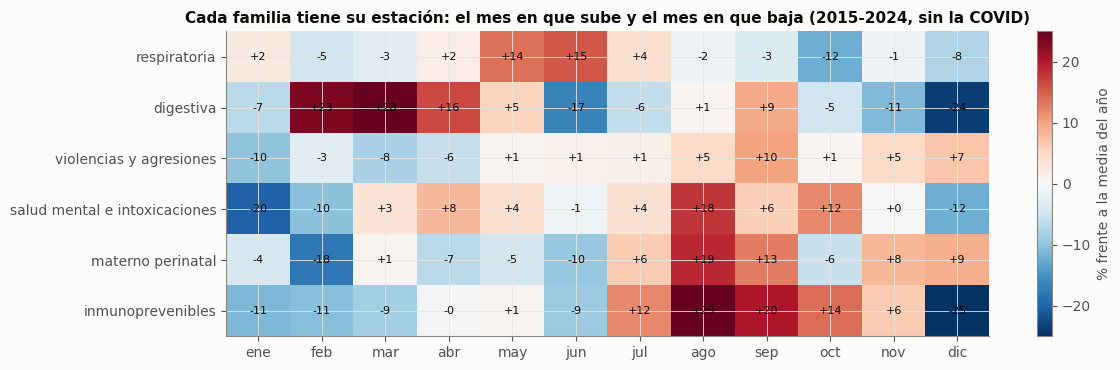

,mes más alto,% en ese mes,mes más bajo,% en ese mes
respiratoria,jun,15.0,oct,-12.0
digestiva,mar,28.0,dic,-24.0
violencias_y_agresiones,sep,10.0,ene,-10.0
salud_mental_e_intoxicaciones,ago,18.0,ene,-20.0
materno_perinatal,ago,19.0,feb,-18.0
inmunoprevenibles,ago,29.0,dic,-25.0


In [2]:
crudas = ix.series_sivigila().loc["2015":FIN]
crudas = crudas[(crudas.index < "2020-03-15") | (crudas.index > "2021-12-31")]
indice_mes = {}
for fam, miembros in ix.FAMILIAS.items():
    cols = [f"{ev}_{var or 'casos'}" for ev, var in miembros]
    x = np.log1p(crudas[cols]); x = x - x.groupby(x.index.year).transform("mean")      # forma del ano, sin el nivel de cada ano
    indice_mes[fam] = (np.exp(x.mean(axis=1).groupby(x.index.month).mean()) - 1) * 100
H = pd.DataFrame(indice_mes).T
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(H.values, cmap="RdBu_r", vmin=-25, vmax=25, aspect="auto")
ax.set_xticks(range(12), MESES); ax.set_yticks(range(len(H)), [f.replace("_", " ") for f in H.index])
for (i, j), v in np.ndenumerate(H.values): ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=8, color=TINTA)
plt.colorbar(im, ax=ax, label="% frente a la media del año"); ax.set_title("Cada familia tiene su estación: el mes en que sube y el mes en que baja (2015-2024, sin la COVID)")
plt.tight_layout(); plt.show()
pd.DataFrame({"mes más alto": [MESES[int(np.argmax(r))] for r in H.values], "% en ese mes": H.max(axis=1).round(0).values,
              "mes más bajo": [MESES[int(np.argmin(r))] for r in H.values], "% en ese mes ": H.min(axis=1).round(0).values}, index=H.index)

**Lectura.** Cada familia tiene su propia estación, pero no hay seis calendarios distintos: la digestiva alcanza su máximo en marzo (+28 %) y su mínimo en diciembre (−24 %); la respiratoria sube hasta +15 % en junio y baja hasta −12 % en octubre; las violencias llegan a +10 % en septiembre y a −10 % en enero; y tres familias, salud mental e intoxicaciones (+18 %), materno-perinatal (+19 %) e inmunoprevenibles (+29 %), coinciden en agosto como mes más alto. La amplitud también difiere: las inmunoprevenibles y la digestiva oscilan unos 50 puntos de punta a punta, las violencias solo unos 20.

El pico respiratorio de junio coincide con la temporada de lluvias de mitad de año, lo que es compatible con el mecanismo del clima, pero esta figura no lo prueba: muestra el mes, no la causa. La cobertura que sí se desprende de la figura es parcial. La respiratoria y la digestiva no suben a la vez, de modo que una sola serie (la IRA) deja sin explicar el máximo de marzo; en cambio el máximo de agosto de tres familias se explicaría con la misma señal de calendario, y un modelo que las use como variables separadas tendría que demostrar que aportan algo más que el mes.

---
# 2. Correlación entre familias, semana a semana

Si las familias se movieran juntas, seis índices serían uno solo repetido. Se mide la correlación de las
anomalías semanales (2012-2024, sin la COVID).

In [3]:
C_ = FAM.dropna().corr().round(2)
C_.index = C_.columns = [c.replace("_", " ") for c in C_.columns]; C_

,respiratoria,digestiva,violencias y agresiones,salud mental e intoxicaciones,materno perinatal,inmunoprevenibles
respiratoria,1.00,0.19,-0.03,0.05,-0.06,0.13
digestiva,0.19,1.00,-0.10,0.09,-0.05,0.17
violencias y agresiones,-0.03,-0.10,1.00,0.06,0.02,0.05
salud mental e intoxicaciones,0.05,0.09,0.06,1.00,0.03,0.04
materno perinatal,-0.06,-0.05,0.02,0.03,1.00,-0.02
inmunoprevenibles,0.13,0.17,0.05,0.04,-0.02,1.00


**Lectura.** Las seis familias son casi independientes semana a semana: la correlación más alta es la de respiratoria con digestiva (0,19), seguida de inmunoprevenibles con digestiva (0,17) y con respiratoria (0,13). Las demás están entre −0,10 y 0,09.

Esto importa para el modelo: seis índices casi independientes aportan seis señales distintas, no la misma señal repetida seis veces, y no se pisan entre sí como ocurría con las 49 variables sueltas de los cuadernos anteriores. El resultado habla de las anomalías semanales de la notificación; no dice que las enfermedades no compartan causas, porque una causa común con rezagos distintos para cada familia no aparecería como correlación simultánea.

---
# 3. Cada familia contra el hospital

Desenlaces:
- el **triage total** sin calendario ni escalones de la red (2022-2024);
- los **ingresos por capítulo de diagnóstico** del hospital (2021-2024): respiratorio, infecciosas, digestivo,
  trauma, embarazo y mental.

Cada prueba es `desenlace(t) ~ familia(t − rezago) + mes + año`, con rezago de 0 a 4 semanas, errores robustos a
la autocorrelación (HAC) y corrección de Benjamini-Hochberg con q = 0,10 dentro de cada desenlace.

In [4]:
dx = pd.read_parquet(RAIZ / "salidas/perfil_dx_diario.parquet"); dx["dia"] = pd.to_datetime(dx.dia)
print("capítulos disponibles:", sorted(dx.capitulo.unique()))
CAP = {"respiratorio": "X Respiratorio", "infecciosas": "I Infecciosas y parasitarias", "digestivo": "XI Digestivo",
       "trauma": "XIX Traumatismos y envenenamientos", "embarazo": "XV Embarazo, parto y puerperio"}
ment = [c for c in dx.capitulo.unique() if c.startswith("V ")]
if ment: CAP["mental"] = ment[0]
dias = pd.date_range("2020-01-01", FIN)
DES = {"triage total": desenlace_semanal().y.loc[:FIN]}
for k, c in CAP.items():
    s = dx[dx.capitulo == c].set_index("dia").n.reindex(dias).fillna(0)
    DES[f"ingresos {k}"] = np.log1p(ix.semana(s, "sum")).loc["2021-01-01":FIN]
def barrido(y, X, rezagos=range(0, 5)):
    filas = []; idx = y.dropna().index
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    anio = pd.get_dummies(pd.Index(idx.year), prefix="a", drop_first=True).set_index(idx).astype(float)
    for c in X:
        xs = (X[c] - X[c].mean()) / X[c].std()
        for L in rezagos:
            D = pd.concat([y.rename("y"), xs.shift(L).rename("x"), mes, anio], axis=1).loc[idx].dropna()
            if len(D) < 50 or D.x.std() == 0: continue
            D = D.loc[:, (D != 0).any()]                                     # un ano sin semanas validas deja una columna de ceros
            r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
            filas.append({"familia": c, "rezago": L, "efecto %": 100 * (np.exp(r.params["x"]) - 1), "p": r.pvalues["x"], "n": len(D)})
    T = pd.DataFrame(filas); T["q"] = multipletests(T.p, method="fdr_bh")[1]; return T
RES = {k: barrido(y, FAM) for k, y in DES.items()}
pd.DataFrame({k: {"pruebas": len(T), "p < 0,05": int((T.p < .05).sum()), "azar esperaría": round(.05 * len(T), 1),
                  "sobreviven BH": int((T.q < .10).sum())} for k, T in RES.items()}).T

capítulos disponibles: ['I Infecciosas y parasitarias', 'II Tumores', 'III Sangre e inmunidad', 'IV Endocrinas y metabolicas', 'IX Circulatorio', 'V Mentales y del comportamiento', 'VI Sistema nervioso', 'VII Ojo', 'VIII Oido', 'X Respiratorio', 'XI Digestivo', 'XII Piel', 'XIII Osteomuscular', 'XIV Genitourinario', 'XIX Traumatismos y envenenamientos', 'XV Embarazo, parto y puerperio', 'XVI Perinatal', 'XVII Malformaciones congenitas', 'XVIII Sintomas y signos', 'XX Causas externas', 'XXI Factores que influyen en la salud', 'XXII Codigos especiales (COVID-19)']


,pruebas,"p < 0,05",azar esperaría,sobreviven BH
triage total,30.0,6.0,1.5,4.0
ingresos respiratorio,30.0,4.0,1.5,0.0
ingresos infecciosas,30.0,4.0,1.5,0.0
ingresos digestivo,30.0,2.0,1.5,0.0
ingresos trauma,30.0,3.0,1.5,0.0
ingresos embarazo,30.0,11.0,1.5,5.0
ingresos mental,30.0,3.0,1.5,2.0


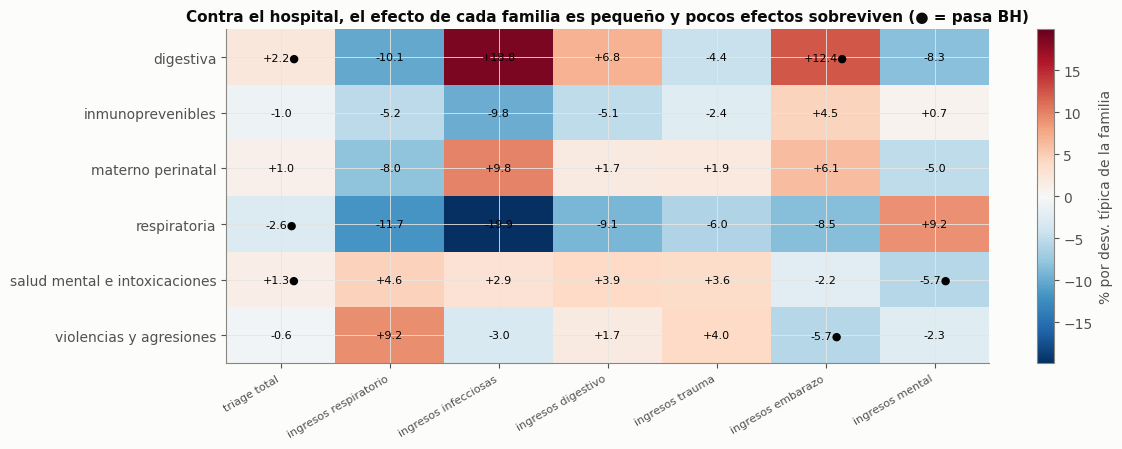

familia  rezago  efecto %      q  \
triage total      15  salud_mental_e_intoxicaciones       0     1.308  0.028   
                  3                    respiratoria       3    -2.643  0.028   
                  5                       digestiva       0     2.239  0.034   
                  4                    respiratoria       4    -1.786  0.057   
ingresos embarazo 5                       digestiva       0    12.394  0.009   
                  6                       digestiva       1    10.970  0.013   
                  14        violencias_y_agresiones       4    -5.681  0.013   
                  13        violencias_y_agresiones       3    -5.128  0.013   
                  7                       digestiva       2     9.711  0.013   
ingresos mental   19  salud_mental_e_intoxicaciones       4    -5.732  0.058   
                  17  salud_mental_e_intoxicaciones       2     5.660  0.058   

                        n  
triage total      15  147  
                  3   147  
                  5   147  
                  4   147  
ingresos embarazo 5   157  
                  6   156  
                  14  153  
                  13  154  
                  7   155  
ingresos mental   19  153  
                  17  155

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.6))
M = pd.DataFrame({k: T.loc[T.groupby("familia")["p"].idxmin()].set_index("familia")["efecto %"] for k, T in RES.items()})
Q = pd.DataFrame({k: T.loc[T.groupby("familia")["p"].idxmin()].set_index("familia")["q"] for k, T in RES.items()})
lim = np.nanmax(np.abs(M.values))
im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for (i, j), v in np.ndenumerate(M.values): ax.text(j, i, f"{v:+.1f}{'●' if Q.values[i, j] < .10 else ''}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(M.shape[1]), M.columns, rotation=30, ha="right", fontsize=8); ax.set_yticks(range(M.shape[0]), [f.replace("_", " ") for f in M.index])
plt.colorbar(im, ax=ax, label="% por desv. típica de la familia"); ax.set_title("Contra el hospital, el efecto de cada familia es pequeño y pocos efectos sobreviven (● = pasa BH)")
plt.tight_layout(); plt.show()
pd.concat({k: T[T.q < .10].sort_values("p")[["familia", "rezago", "efecto %", "q", "n"]] for k, T in RES.items()}).round(3)

In [6]:
# lo que dice la familia respiratoria de la ciudad sobre el respiratorio del hospital, rezago por rezago
T = RES["ingresos respiratorio"]; T[T.familia == "respiratoria"].round(3)

,familia,rezago,efecto %,p,n,q
0,respiratoria,0,11.286,0.114,157,0.364
1,respiratoria,1,4.263,0.497,156,0.670
2,respiratoria,2,-5.176,0.379,155,0.665
3,respiratoria,3,-9.951,0.099,154,0.364
4,respiratoria,4,-11.700,0.024,153,0.206


**Lectura. Contra el hospital, la señal de las familias es débil y hay que leerla con cuidado.**

Contra el triage total sobreviven 4 de 30 pruebas a la corrección de Benjamini-Hochberg (con 6 pruebas por debajo de p = 0,05 cuando el azar esperaría 1,5), todas con efectos de 1 a 3 %: salud mental e intoxicaciones de la misma semana (+1,3 %), digestiva de la misma semana (+2,2 %) y respiratoria con signo negativo a 3 y 4 semanas (−2,6 % y −1,8 %). El signo negativo de la respiratoria no tiene un mecanismo que lo explique y no se interpreta.

Contra los ingresos del hospital por capítulo de diagnóstico no sobrevive ninguna prueba en respiratorio, infecciosas, digestivo ni trauma. La familia respiratoria de la ciudad tiene sobre los ingresos respiratorios del hospital un efecto de +11,3 % en la misma semana y +4,3 % a una semana, con p de 0,114 y 0,497 (tabla anterior): el mismo signo que el índice compuesto de vigilancia del cuaderno 13 (+8,7 % a +10,6 % a una semana, p = 0,055 en 2025), pero ninguna de las dos mediciones pasa el umbral. Los ingresos son una fracción del triage y tienen pocos casos por semana, lo que limita la potencia.

Sobreviven además cinco pruebas en ingresos por embarazo (la digestiva a 0, 1 y 2 semanas, +9,7 a +12,4 %, y las violencias a 3 y 4 semanas, −5,1 y −5,7 %) y dos en ingresos de salud mental, con signos opuestos a 2 y 4 semanas (+5,7 % y −5,7 %). Ninguna tiene un mecanismo que la explique. En el embarazo hay 11 de 30 pruebas con p < 0,05, contra 1,5 esperadas, lo que apunta a estacionalidad compartida que el mes fijo no absorbe del todo, y se tratan como coincidencia de temporada.

**Para el total, las familias suman poco, igual que el clima.** Su lugar natural es el modelo jerárquico, donde cada familia acompaña a su parte del triage, y la sección 5 muestra por qué: el efecto está concentrado en bandas de edad.

---
# 4. Clima y familia: el primer eslabón de la cadena

La cadena «factor externo → enfermedad en la ciudad → demanda del hospital» empieza aquí: ¿qué familias responden
al clima? Se usan los índices de clima del cuaderno 17 (cuatro de estado, tres de cambio brusco, la racha seca y
los días desde la última semana muy lluviosa), 2012-2024, con rezagos de 0 a 6 semanas.

In [7]:
IC = ix.indices_clima()
RC = {fam: barrido(FAM[fam].dropna(), IC, range(0, 7)) for fam in FAM}
rc = pd.DataFrame({fam: {"pruebas": len(T), "sobreviven BH": int((T.q < .10).sum()),
                         "más fuerte": (lambda t: f"{t.familia} a {t.rezago} sem: {t['efecto %']:+.1f} %")(T.loc[T.p.idxmin()])} for fam, T in RC.items()}).T
rc

,pruebas,sobreviven BH,más fuerte
respiratoria,63,4,racha_seca a 3 sem: -9.5 %
digestiva,63,12,dias_desde_semana_muy_lluviosa a 0 sem: +15.7 %
violencias_y_agresiones,63,1,estado_2 a 0 sem: -11.5 %
salud_mental_e_intoxicaciones,63,0,cambio_3 a 1 sem: -7.3 %
materno_perinatal,63,0,cambio_1 a 2 sem: -12.8 %
inmunoprevenibles,63,5,dias_desde_semana_muy_lluviosa a 6 sem: +23.6 %


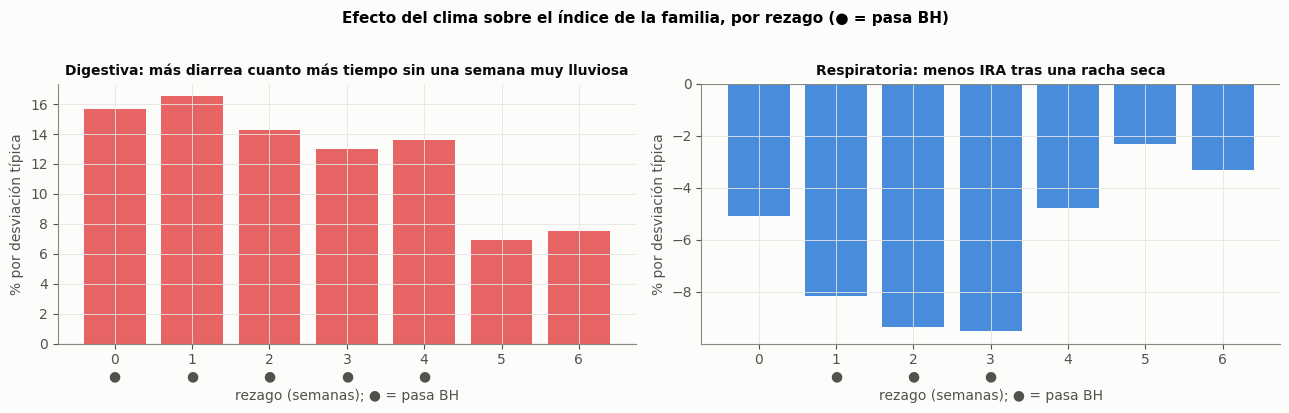

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, (fam, col, ind, tit) in zip(axes, [("digestiva", ROJO, "dias_desde_semana_muy_lluviosa", "Digestiva: más diarrea cuanto más tiempo sin una semana muy lluviosa"),
                                          ("respiratoria", AZUL, "racha_seca", "Respiratoria: menos IRA tras una racha seca")]):
    T = RC[fam]; T = T[T.familia == ind].sort_values("rezago")
    ax.bar(T.rezago, T["efecto %"], color=col, alpha=.85)
    ax.set_xticks(T.rezago, [f"{r}\n●" if q < .10 else f"{r}" for r, q in zip(T.rezago, T.q)])
    ax.axhline(0, color=MUDO, lw=.8); ax.set_xlabel("rezago (semanas); ● = pasa BH"); ax.set_ylabel("% por desviación típica"); ax.set_title(tit, fontsize=10)
plt.suptitle("Efecto del clima sobre el índice de la familia, por rezago (● = pasa BH)", y=1.02, fontsize=11, fontweight="bold"); plt.tight_layout(); plt.show()

In [9]:
# las pruebas del clima que sobreviven a BH (q < 0,10), rezago por rezago, para cada familia
sob = pd.concat({fam: T[T.q < .10].sort_values(["familia", "rezago"])[["familia", "rezago", "efecto %", "p", "q"]].rename(columns={"familia": "índice de clima"}) for fam, T in RC.items()})
sob.round(3)

índice de clima  rezago  efecto %  \
respiratoria            3                         estado_1       3    -8.054   
                        50                      racha_seca       1    -8.156   
                        51                      racha_seca       2    -9.349   
                        52                      racha_seca       3    -9.521   
digestiva               56  dias_desde_semana_muy_lluviosa       0    15.689   
                        57  dias_desde_semana_muy_lluviosa       1    16.526   
                        58  dias_desde_semana_muy_lluviosa       2    14.265   
                        59  dias_desde_semana_muy_lluviosa       3    13.013   
                        60  dias_desde_semana_muy_lluviosa       4    13.575   
                        9                         estado_2       2     9.921   
                        10                        estado_2       3    10.929   
                        24                        estado_4       3    -7.200   
                        50                      racha_seca       1     6.849   
                        51                      racha_seca       2     6.672   
                        52                      racha_seca       3     6.599   
                        55                      racha_seca       6    10.783   
violencias_y_agresiones 7                         estado_2       0   -11.497   
inmunoprevenibles       58  dias_desde_semana_muy_lluviosa       2    17.943   
                        59  dias_desde_semana_muy_lluviosa       3    21.046   
                        60  dias_desde_semana_muy_lluviosa       4    21.304   
                        61  dias_desde_semana_muy_lluviosa       5    21.782   
                        62  dias_desde_semana_muy_lluviosa       6    23.570   

                                p      q  
respiratoria            3   0.002  0.034  
                        50  0.005  0.080  
                        51  0.001  0.034  
                        52  0.000  0.014  
digestiva               56  0.000  0.003  
                        57  0.000  0.003  
                        58  0.000  0.004  
                        59  0.000  0.006  
                        60  0.000  0.004  
                        9   0.018  0.099  
                        10  0.016  0.099  
                        24  0.016  0.099  
                        50  0.019  0.099  
                        51  0.013  0.099  
                        52  0.015  0.099  
                        55  0.002  0.022  
violencias_y_agresiones 7   0.001  0.062  
inmunoprevenibles       58  0.000  0.004  
                        59  0.000  0.001  
                        60  0.000  0.000  
                        61  0.000  0.000  
                        62  0.000  0.000

**Lectura. El clima sí mueve a las enfermedades transmisibles de la ciudad.** Es el primer eslabón de la cadena «factor externo → enfermedad → demanda».

- **Digestiva: 12 de 63 pruebas sobreviven.** Cuanto más tiempo pasa desde la última semana muy lluviosa, más EDA: +15,7 % por desviación típica en la misma semana, y entre +13,0 % y +16,5 % de 0 a 4 semanas, todas con q ≤ 0,006. La racha seca también sube la digestiva a 6 semanas (+10,8 %). El gatillo es una duración, no un nivel: lo que pesa es cuánto lleva la ciudad sin lluvia fuerte.
- **Respiratoria: 4 de 63.** La racha seca la baja entre −8,2 % y −9,5 % a 1, 2 y 3 semanas (el mayor, −9,5 % a 3 semanas, con q = 0,014). Es el reflejo del vínculo entre humedad e IRA del cuaderno 17: los periodos secos largos se acompañan de menos consultas respiratorias a las dos o tres semanas.
- **Inmunoprevenibles (varicela): 5 de 63**, todas con los días desde la última semana muy lluviosa, de 2 a 6 semanas (+17,9 % a +23,6 %).
- **Violencias: 1 prueba** (uno de los índices de estado, a rezago 0, −11,5 %, q = 0,062). **Salud mental y materno-perinatal: 0.**

En conjunto, el clima actúa sobre las enfermedades transmisibles (respiratoria, digestiva, varicela) y no sobre las violencias, la salud mental ni lo materno-perinatal, que es lo esperable por mecanismo y le da sentido a separar familias. Dos cautelas: los índices de clima tienen estructura estacional que el mes fijo absorbe solo en parte, y ni la digestiva ni la varicela tienen una explicación causal probada: «agua y sequía» es la hipótesis plausible, no una conclusión.

---
# 5. El efecto por banda de edad

Un efecto que afecta a los niños pequeños pesa poco sobre el total, porque los niños de 0 a 4 años son una
fracción pequeña del triage del hospital. Con los datos agregados por banda de edad (0-4, 5-14, 15-44, 45-64 y
65 o más) se pueden hacer dos comprobaciones.

**5.1** En la ciudad, la IRA y la EDA vienen separadas por grupo de edad: se mide si el clima las mueve igual.

**5.2** En el hospital, se repite la prueba de la familia contra el triage, pero con el desenlace de cada banda de
edad (sin calendario ni escalones de la red, 2022-2024, la misma construcción del triage total).

In [10]:
def anom_est(s):
    z = ix.anomalia_operativa(s); z = (z - z.loc[:FIN].mean()) / z.loc[:FIN].std()
    z[(z.index >= "2020-03-15") & (z.index <= "2021-12-31")] = np.nan; return z.loc[:FIN]
EDAD = pd.DataFrame({"IRA 0-4": anom_est(S["995_consultas_ira_0_4"]), "IRA 60+": anom_est(S["995_consultas_ira_60_mas"]),
                     "IRA total": anom_est(S["995_consultas_ira_total"]), "EDA 0-4": anom_est(S["998_casos_eda_0_4"]),
                     "EDA total": anom_est(S["998_casos_eda_total"])})
print("Correlación semanal entre las series por edad:"); display(EDAD.corr().round(2))
RE = {c: barrido(EDAD[c].dropna(), IC, range(0, 7)) for c in EDAD}
pd.DataFrame({c: {"pruebas": len(T), "sobreviven BH": int((T.q < .10).sum()),
                  "más fuerte": (lambda t: f"{t.familia} a {t.rezago} sem: {t['efecto %']:+.1f} % (q = {t.q:.3f})")(T.loc[T.p.idxmin()])} for c, T in RE.items()}).T

Correlación semanal entre las series por edad:


,IRA 0-4,IRA 60+,IRA total,EDA 0-4,EDA total
IRA 0-4,1.00,0.52,0.78,0.44,0.18
IRA 60+,0.52,1.00,0.87,-0.12,0.06
IRA total,0.78,0.87,1.00,0.06,0.12
EDA 0-4,0.44,-0.12,0.06,1.00,0.69
EDA total,0.18,0.06,0.12,0.69,1.00


,pruebas,sobreviven BH,más fuerte
IRA 0-4,63,8,estado_2 a 2 sem: +11.5 % (q = 0.040)
IRA 60+,63,0,racha_seca a 3 sem: -11.0 % (q = 0.105)
IRA total,63,7,racha_seca a 2 sem: -12.1 % (q = 0.015)
EDA 0-4,63,11,dias_desde_semana_muy_lluviosa a 2 sem: +14.3 ...
EDA total,63,19,dias_desde_semana_muy_lluviosa a 0 sem: +15.9 ...


In [11]:
# el efecto de la racha seca, rezago por rezago, en la IRA de niños y de mayores
det = pd.concat({c: RE[c][RE[c].familia == "racha_seca"].set_index("rezago")[["efecto %", "q"]].round(3) for c in ["IRA 0-4", "IRA 60+", "IRA total"]}, axis=1)
det

IRA 0-4         IRA 60+        IRA total       
       efecto %      q efecto %      q  efecto %      q
rezago                                                 
0        -8.314  0.125   -3.313  0.870    -9.689  0.070
1        -9.795  0.060   -7.296  0.358   -12.227  0.015
2        -9.541  0.040  -10.377  0.105   -12.079  0.015
3        -8.068  0.040  -10.968  0.105   -10.518  0.015
4        -2.880  0.646   -5.973  0.424    -5.497  0.338
5        -1.099  0.833   -1.678  0.949    -2.758  0.763
6        -2.239  0.725   -3.655  0.870    -3.593  0.741

**Lectura.** El clima mueve la IRA de los niños y no la de los mayores. En la serie de 0 a 4 años sobreviven 8 de 63 pruebas, con el índice de estado 2 a dos semanas como la más fuerte (+11,5 %, q = 0,040); en la de 60 años o más sobreviven 0, y la más fuerte, la racha seca a tres semanas (−11,0 %), queda en q = 0,105. La tabla por rezagos muestra que la racha seca baja la IRA de los dos grupos con efectos del mismo orden, pero solo en los niños pasa la corrección. Entre las dos series la correlación semanal es de 0,52, de modo que no son la misma señal.

Para la EDA ocurre al revés: la de 0 a 4 años (11 pruebas) y la de todas las edades (19 pruebas) responden a los días sin semana muy lluviosa con efectos parecidos (+14,3 % y +15,9 %), así que el efecto digestivo no es exclusivo de la infancia. El límite de este análisis es la potencia: la IRA de 60 años o más tiene el mismo número de semanas, pero un efecto de cerca de −11 % con q de 0,105 es una diferencia de grado y no una ausencia demostrada.

In [12]:
# triage por banda de edad: misma construcción que el triage total (sin calendario, sin escalones de la red, mismas semanas)
te = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet"); te["dia"] = pd.to_datetime(te.dia)
dd = pd.date_range("2020-01-01", "2026-09-19")
tri = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia)).set_index("dia").triages.reindex(dd).astype(float)
tri["2024-03-19":"2024-03-21"] = np.nan                                  # caida del registro
cal = (pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(dd)[dz.CAL]
         .apply(pd.to_numeric, errors="coerce").fillna(0))
completas = dz._semana(tri.notna().astype(int)) == 7
cal_w = dz._semana(cal).loc[dz.INICIO:dz.FIN]
BANDAS = ["0-4", "5-14", "15-44", "45-64", "65-+"]
Bd = {}
for b in BANDAS:
    s = te[te.banda.eq(b)].groupby("dia").n.sum().reindex(dd).fillna(0).astype(float); s[tri.isna()] = np.nan
    Bd[b] = dz._residuo(dz._semana(s).where(completas).loc[dz.INICIO:dz.FIN], cal_w).loc[:FIN]
Bd = pd.DataFrame(Bd)
peso = (te[te.banda.isin(BANDAS)].groupby("banda").n.sum() / te[te.banda.isin(BANDAS)].n.sum() * 100).reindex(BANDAS).round(1)
RB = {b: barrido(Bd[b], FAM) for b in BANDAS}
print("Peso de cada banda en el triage 2020-2026 (%):"); display(peso.to_frame("% del triage").T)
pd.DataFrame({b: {"semanas": int(Bd[b].notna().sum()), "pruebas": len(T), "p < 0,05": int((T.p < .05).sum()),
                  "azar esperaría": round(.05 * len(T), 1), "sobreviven BH": int((T.q < .10).sum())} for b, T in RB.items()}).T

Peso de cada banda en el triage 2020-2026 (%):


banda,0-4,5-14,15-44,45-64,65-+
% del triage,3.1,4.4,54.5,18.5,19.5


,semanas,pruebas,"p < 0,05",azar esperaría,sobreviven BH
0-4,147.0,30.0,3.0,1.5,1.0
5-14,147.0,30.0,6.0,1.5,1.0
15-44,147.0,30.0,7.0,1.5,7.0
45-64,147.0,30.0,10.0,1.5,6.0
65-+,147.0,30.0,2.0,1.5,0.0


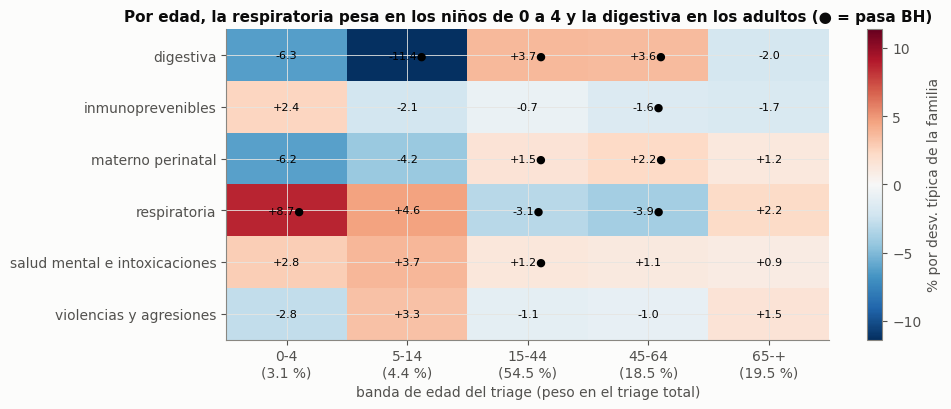

familia  rezago  efecto %      q    n
0-4   0                    respiratoria       0     8.694  0.027  147
5-14  9                       digestiva       4   -11.365  0.004  147
15-44 5                       digestiva       0     3.683  0.004  147
      6                       digestiva       1     2.661  0.010  147
      3                    respiratoria       3    -3.119  0.027  147
      4                    respiratoria       4    -2.351  0.040  147
      15  salud_mental_e_intoxicaciones       0     1.245  0.040  147
      7                       digestiva       2     2.588  0.074  147
      24              materno_perinatal       4     1.533  0.078  147
45-64 5                       digestiva       0     3.617  0.018  147
      3                    respiratoria       3    -3.871  0.021  147
      24              materno_perinatal       4     2.245  0.025  147
      21              materno_perinatal       1     2.157  0.025  147
      2                    respiratoria       2    -3.235  0.027  147
      25              inmunoprevenibles       0    -1.578  0.031  147

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
M2 = pd.DataFrame({b: T.loc[T.groupby("familia")["p"].idxmin()].set_index("familia")["efecto %"] for b, T in RB.items()})
Q2 = pd.DataFrame({b: T.loc[T.groupby("familia")["p"].idxmin()].set_index("familia")["q"] for b, T in RB.items()})
lim = np.nanmax(np.abs(M2.values))
im = ax.imshow(M2.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for (i, j), v in np.ndenumerate(M2.values): ax.text(j, i, f"{v:+.1f}{'●' if Q2.values[i, j] < .10 else ''}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(M2.shape[1]), [f"{b}\n({peso[b]} %)" for b in M2.columns]); ax.set_yticks(range(M2.shape[0]), [f.replace("_", " ") for f in M2.index])
plt.colorbar(im, ax=ax, label="% por desv. típica de la familia"); ax.set_xlabel("banda de edad del triage (peso en el triage total)")
ax.set_title("Por edad, la respiratoria pesa en los niños de 0 a 4 y la digestiva en los adultos (● = pasa BH)")
plt.tight_layout(); plt.show()
pd.concat({b: T[T.q < .10].sort_values("p")[["familia", "rezago", "efecto %", "q", "n"]] for b, T in RB.items()}).round(3)

**Lectura. Por edad, el efecto aparece donde el total lo diluye.**

- **0 a 4 años (3,1 % del triage):** la familia respiratoria de la misma semana sube el triage de esa banda un +8,7 % por desviación típica (q = 0,027), la única prueba que sobrevive en la banda. En el total ese efecto no aparece: un +8,7 % sobre el 3,1 % del volumen aporta solo unos 0,3 % al total, invisible bajo el ruido semanal. Es la dilución que el proyecto había anticipado, ahora medida con una banda de edad y no solo con el capítulo de diagnóstico.
- **15 a 44 y 45 a 64 años (73 % del triage entre las dos):** son las que llevan los resultados del total. La digestiva de la misma semana sube el triage +3,7 % y +3,6 %, la respiratoria a 2-4 semanas lo baja entre −2,4 % y −3,9 %, y salud mental (+1,2 %) y materno-perinatal (+1,5 % y +2,2 %) aparecen en una o en las dos. Son 7 y 6 pruebas que sobreviven, con 1,5 esperadas por azar.
- **65 años o más (19,5 %):** ninguna prueba sobrevive, y solo 2 pasan p < 0,05, que es lo que el azar da.
- **5 a 14 años:** sobrevive una sola prueba, la digestiva a 4 semanas con −11,4 %. Es negativa, está aislada y no tiene mecanismo; la banda es el 4,4 % del triage y se trata como azar.

La cautela principal es el número de pruebas: son 150 en total entre las cinco bandas, con la corrección aplicada dentro de cada banda y no sobre el conjunto. Con la corrección conjunta pasarían menos. La concentración en adultos, además, no implica que los adultos «respondan» a las enfermedades que miden las familias: la digestiva y la salud mental pueden estar capturando calendario (el mes fijo no lo absorbe todo).

In [14]:
# la serie por edad que corresponde a cada banda (0-4 con IRA 0-4; 65+ con IRA 60+): una sola prueba por banda, a rezagos 0-4
pares = {"0-4": "IRA 0-4", "65-+": "IRA 60+"}
filas = []
for b, c in pares.items():
    T = barrido(Bd[b], EDAD[[c]].dropna())
    for _, r in T.iterrows(): filas.append({"banda": b, "serie": c, "rezago": int(r.rezago), "efecto %": round(r["efecto %"], 2), "p": round(r.p, 3)})
PAR = pd.DataFrame(filas); PAR["q (10 pruebas)"] = multipletests(PAR.p, method="fdr_bh")[1].round(3)
PAR

,banda,serie,rezago,efecto %,p,q (10 pruebas)
0,0-4,IRA 0-4,0,5.33,0.053,0.177
1,0-4,IRA 0-4,1,2.76,0.319,0.638
2,0-4,IRA 0-4,2,-0.76,0.786,0.876
3,0-4,IRA 0-4,3,-2.39,0.423,0.705
4,0-4,IRA 0-4,4,-0.33,0.893,0.893
5,65-+,IRA 60+,0,2.86,0.008,0.080
6,65-+,IRA 60+,1,2.24,0.025,0.125
7,65-+,IRA 60+,2,1.16,0.254,0.635
8,65-+,IRA 60+,3,0.32,0.788,0.876
9,65-+,IRA 60+,4,0.41,0.706,0.876


**Lectura.** Esta comparación empareja cada banda con la serie de la ciudad de su misma edad, y se definió después de ver el barrido anterior, por lo que no es una prueba independiente. Con la corrección sobre sus 10 pruebas, la IRA de 60 años o más de la misma semana se asocia con el triage de 65 o más con +2,9 % por desviación típica (p = 0,008, q = 0,080), y a una semana con +2,2 % (q = 0,125): un efecto pequeño, apenas por debajo del umbral, pero con el signo y el rezago que el mecanismo pide. En los niños, la IRA de 0 a 4 años da +5,3 % en la misma semana (p = 0,053, q = 0,177), sin pasar el umbral: el índice de la familia completa (+8,7 %) captura el efecto mejor que la serie emparejada, lo que sugiere que la IRAG y la IRA de los mayores también aportan a la demanda pediátrica o que la serie por edad tiene más ruido.

El hallazgo de los mayores es una pista, no una confirmación: aquí solo se usan datos hasta 2024, no se ha medido fuera de muestra y las bandas de edad del hospital (65 o más) no coinciden con las de la vigilancia (60 o más).

---
# 6. Episodios: epidemias y otras enfermedades de Manizales

El promedio de trece años de datos mezcla meses sin nada con semanas en que ocurre algo. Un efecto que dura siete
semanas y ocurre una vez desaparece en una regresión de todo el periodo. Aquí se toman episodios concretos y se
trata cada uno con la pregunta del mecanismo: qué reloj tiene, qué lo dispara, bajo qué condición y en quién.

## 6.1 Varicela durante el paro nacional de 2021

En el cuaderno 20 el paro nacional (2021-04-28 a 2021-06-15) aparecía asociado a más varicela (+0,67 desviaciones
típicas). Un efecto grande, sobre una sola ventana. Se revisa de tres maneras: se reproduce, se compara con los
conteos crudos y se pregunta cuánto efecto producirían ventanas del mismo tamaño puestas al azar en la serie.

In [15]:
R = ix.regimenes_diarios()
W = R.resample("W-SAT").mean(); W.index -= pd.Timedelta(days=6)
def ajuste(y, x, maxlags=8):
    # efecto del estado x sobre el índice y, con mes fijo y tendencia lineal (un estado largo no cabe con año fijo)
    idx = y.dropna().index
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    tend = pd.Series(np.arange(len(idx)) / 52, index=idx, name="tendencia")
    D = pd.concat([y.rename("y"), x.rename("x"), mes, tend], axis=1).loc[idx].dropna()
    r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return r.params["x"], r.pvalues["x"], int((D.x > 0).sum())
def permutar(y, x, margen=26):
    # desplaza circularmente el estado por toda la serie: conserva su duración y su forma, rompe su fecha
    idx = y.dropna().index; v = x.reindex(idx).fillna(0).values
    return np.array([ajuste(y, pd.Series(np.roll(v, k), index=idx))[0] for k in range(margen, len(idx) - margen)])
yv = FAM_C["inmunoprevenibles"]
b_paro, p_paro, n_paro = ajuste(yv, W.paro_nacional_2021)
perm_paro = permutar(yv, W.paro_nacional_2021)
v = S["831_casos"]; en_paro = pd.Series((v.index >= "2021-04-25") & (v.index <= "2021-06-13"), index=v.index)
cont = {"semanas del paro 2021": v[en_paro].mean(), "resto de 2021": v["2021"][~en_paro["2021"]].mean()}
for a in (2019, 2020, 2021, 2022): cont[f"promedio de todo {a}"] = v[str(a)].mean()
cont["ene-jun de 2021"] = v["2021-01":"2021-06"].mean(); cont["jul-dic de 2021"] = v["2021-07":"2021-12"].mean()
for a in (2022, 2023, 2024):
    m = v[str(a)]; p = (m.index >= f"{a}-04-25") & (m.index <= f"{a}-06-13")
    cont[f"mismas semanas de {a}"] = m[p].mean(); cont[f"resto de {a}"] = m[~p].mean()
print(f"Efecto reproducido del paro sobre el índice de inmunoprevenibles: {b_paro:+.2f} desv. típicas (p = {p_paro:.3f}), {n_paro} semanas con paro")
print(f"Con la misma ventana desplazada por toda la serie: efecto ≥ al observado en el {100*(perm_paro >= b_paro).mean():.1f} % de las posiciones (de {len(perm_paro)}); desv. típica del efecto al azar = {perm_paro.std():.2f}")
print(f"Efecto en valor absoluto ≥ al observado: {100*(np.abs(perm_paro) >= abs(b_paro)).mean():.1f} %")
pd.Series(cont, name="casos de varicela por semana").round(2).to_frame()

Efecto reproducido del paro sobre el índice de inmunoprevenibles: +0.67 desv. típicas (p = 0.023), 8 semanas con paro
Con la misma ventana desplazada por toda la serie: efecto ≥ al observado en el 17.6 % de las posiciones (de 444); desv. típica del efecto al azar = 0.82
Efecto en valor absoluto ≥ al observado: 39.6 %


,casos de varicela por semana
semanas del paro 2021,1.50
resto de 2021,2.55
promedio de todo 2019,6.73
promedio de todo 2020,2.17
promedio de todo 2021,2.38
promedio de todo 2022,4.52
ene-jun de 2021,1.46
jul-dic de 2021,3.31
mismas semanas de 2022,6.43
resto de 2022,4.22


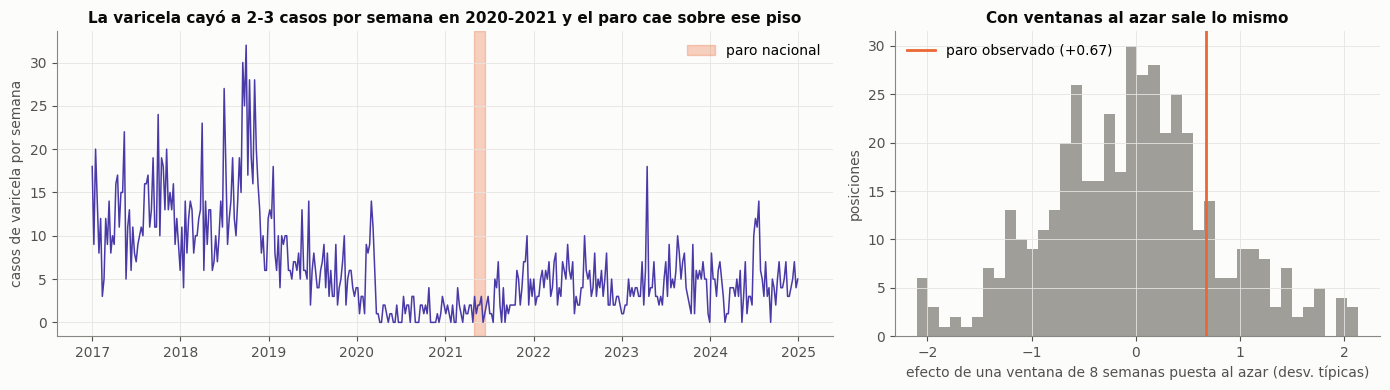

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]; vv = S["831_casos"].loc["2017":"2024"]
ax.plot(vv.index, vv.values, color=VIOLETA, lw=1.1); ax.axvspan(pd.Timestamp("2021-04-28"), pd.Timestamp("2021-06-15"), color=NARANJA, alpha=.3, label="paro nacional")
ax.set_ylabel("casos de varicela por semana"); ax.set_title("La varicela cayó a 2-3 casos por semana en 2020-2021 y el paro cae sobre ese piso"); ax.legend(loc="upper right")
ax = axes[1]; ax.hist(perm_paro, bins=40, color=MUDO, alpha=.8); ax.axvline(b_paro, color=NARANJA, lw=2, label=f"paro observado ({b_paro:+.2f})")
ax.set_xlabel("efecto de una ventana de 8 semanas puesta al azar (desv. típicas)"); ax.set_ylabel("posiciones"); ax.set_title("Con ventanas al azar sale lo mismo"); ax.legend()
plt.tight_layout(); plt.show()

**Lectura. El +0,67 del paro nacional no es un efecto del paro.** Se reproduce el valor (+0,67, p = 0,023, 8 semanas), pero tres comprobaciones lo desarman.

Primero, **la ventana de 8 semanas puesta en cualquier otro lugar de la serie da un efecto igual o mayor en el 17,6 % de las posiciones** (de 444) y la desviación típica del efecto al azar es de 0,82: el valor observado queda dentro de lo que produce el azar. En valor absoluto, el 39,6 % de las posiciones lo iguala o supera. La figura de la derecha lo muestra: la línea del paro cae dentro de la nube.

Segundo, **los conteos crudos van en sentido contrario**: durante el paro la varicela tuvo 1,50 casos por semana frente a 2,55 en el resto de 2021. El índice sube porque se mide contra la media de las 52 semanas anteriores, que en 2021 eran el fondo del desplome de 2019 a 2020; cualquier recuperación aparece como anomalía positiva. Los conteos pasan de 1,46 casos por semana en el primer semestre de 2021 a 3,31 en el segundo, y el promedio de 2022 es de 4,52 (6,73 en 2019 y 2,17 en 2020, tabla). Las mismas semanas de los años siguientes no muestran un patrón estacional estable: 6,43 frente a 4,22 en 2022, pero 3,71 frente a 4,65 en 2023 y 3,29 frente a 4,84 en 2024.

Tercero, **no hay un mecanismo que haga esperar más varicela por un paro**: si algo, un paro que reduce el contacto presencial iría en sentido contrario. El episodio coincide con la reapertura escolar y con la recuperación de la notificación después de la COVID, y este análisis no puede separar el paro de esos dos fenómenos. La conclusión es que el dato no permite afirmar ni descartar un efecto del paro, y que la asociación del cuaderno 20 no debe tomarse como hallazgo.

## 6.2 Salud mental con los desastres

El mismo cuaderno 20 asoció los desastres catalogados con más salud mental (+0,36). Antes de tomarlo como
hallazgo hay que separar qué es cada episodio, porque el catálogo mezcla eventos de un día confirmados, alertas
regionales de meses y temporadas de lluvias cuya fecha y cifras todavía no están verificadas.

In [17]:
de = pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv")
de = de[pd.to_datetime(de.fecha_inicio) < "2025-01-01"]
dd_ = pd.date_range("2010-01-01", "2026-09-30")
def ventana(df):
    s = pd.Series(0.0, index=dd_)
    for _, r in df.iterrows():
        a = pd.Timestamp(r.fecha_inicio); b = pd.Timestamp(r.fecha_fin) if pd.notna(r.fecha_fin) else a; s[a:b] = 1
    w = s.resample("W-SAT").mean(); w.index -= pd.Timedelta(days=6); return w
conf = de[de.calidad_dato.eq("confirmado")]; sin = de[~de.calidad_dato.eq("confirmado")]
Wc, Ws = ventana(conf), ventana(sin)
ym = FAM_C["salud_mental_e_intoxicaciones"]
filas = []
for nom, x in [("todos los desastres catalogados", W.desastre_activo), (f"solo confirmados ({len(conf)} registros)", Wc), (f"fecha aproximada o por verificar ({len(sin)} registros)", Ws)]:
    b, p, n = ajuste(ym, x.reindex(ym.index).fillna(0)); filas.append({"estado": nom, "efecto (desv. típicas)": round(b, 2), "p": round(p, 3), "semanas": n})
for ev, nom in [("356_casos", "intento de suicidio"), ("365_casos", "intoxicaciones")]:
    z = ix.anomalia_operativa(S[ev]); z = ((z - z.loc[:FIN].mean()) / z.loc[:FIN].std()).loc["2012":FIN]
    b, p, n = ajuste(z, W.desastre_activo); filas.append({"estado": f"todos los desastres, solo {nom}", "efecto (desv. típicas)": round(b, 2), "p": round(p, 3), "semanas": n})
perm_des = permutar(ym, W.desastre_activo); b_des = ajuste(ym, W.desastre_activo)[0]
print(f"Desplazando el estado por toda la serie: efecto ≥ al observado ({b_des:+.2f}) en el {100*(perm_des >= b_des).mean():.1f} % de las posiciones; en valor absoluto, {100*(np.abs(perm_des) >= abs(b_des)).mean():.1f} %")
print("Registros confirmados hasta 2024:"); display(conf[["fecha_inicio", "fecha_fin", "tipo_evento", "subtipo", "ambito"]])
pd.DataFrame(filas)

Desplazando el estado por toda la serie: efecto ≥ al observado (+0.36) en el 6.1 % de las posiciones; en valor absoluto, 13.7 %
Registros confirmados hasta 2024:


,fecha_inicio,fecha_fin,tipo_evento,subtipo,ambito
4,2022-10-20,2022-10-20,deslizamiento,multiples_movimientos_en_masa,municipal
5,2023-03-24,2023-04-30,sismo,sismicidad_volcanica,regional
6,2023-03-30,2023-06-27,actividad_volcanica,alerta_naranja_nivel_II,regional
9,2024-07-05,2024-07-05,deslizamiento,movimiento_en_masa,municipal


,estado,efecto (desv. típicas),p,semanas
0,todos los desastres catalogados,0.36,0.016,75
1,solo confirmados (4 registros),0.79,0.015,17
2,fecha aproximada o por verificar (6 registros),0.19,0.121,58
3,"todos los desastres, solo intento de suicidio",0.29,0.107,75
4,"todos los desastres, solo intoxicaciones",0.40,0.008,75


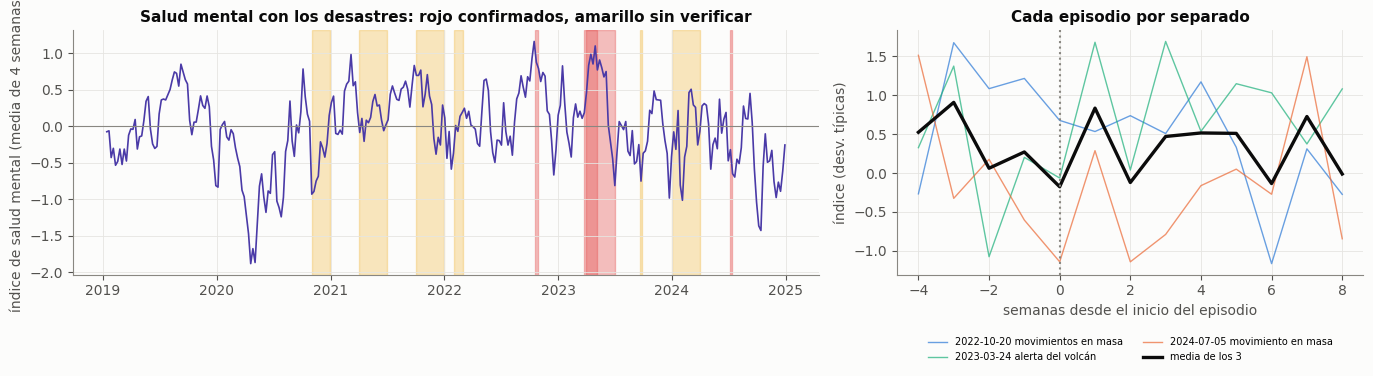

Media del índice, 4 semanas antes: +0.44; semanas 0 a 8 después: +0.29
2022-10-20 movimientos en masa: antes +0.93, después +0.31
2023-03-24 alerta del volcán: antes +0.21, después +0.84
2024-07-05 movimiento en masa: antes +0.19, después -0.28


In [18]:
# estudio de eventos: el indice de salud mental de 4 semanas antes a 8 despues del inicio de cada episodio confirmado
EP = {"2022-10-20 movimientos en masa": "2022-10-20", "2023-03-24 alerta del volcán": "2023-03-24", "2024-07-05 movimiento en masa": "2024-07-05"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]; sub = ym.loc["2019":"2024"]
ax.plot(sub.index, sub.rolling(4, min_periods=2).mean(), color=VIOLETA, lw=1.2)
for _, r in sin.iterrows(): ax.axvspan(pd.Timestamp(r.fecha_inicio), pd.Timestamp(r.fecha_fin) if pd.notna(r.fecha_fin) else pd.Timestamp(r.fecha_inicio) + pd.Timedelta(days=7), color=AMARILLO, alpha=.25)
for _, r in conf.iterrows(): ax.axvspan(pd.Timestamp(r.fecha_inicio), (pd.Timestamp(r.fecha_fin) if pd.notna(r.fecha_fin) else pd.Timestamp(r.fecha_inicio)) + pd.Timedelta(days=7), color=ROJO, alpha=.35)
ax.axhline(0, color=MUDO, lw=.8); ax.set_ylabel("índice de salud mental (media de 4 semanas)")
ax.set_title("Salud mental con los desastres: rojo confirmados, amarillo sin verificar")
ax = axes[1]; tabla = {}
for (nom, f), col in zip(EP.items(), [AZUL, AQUA, NARANJA]):
    a = pd.Timestamp(f); a = a - pd.Timedelta(days=(a.dayofweek + 1) % 7)
    ws = pd.date_range(a - pd.Timedelta(weeks=4), periods=13, freq="7D"); vals = ym.reindex(ws).values; tabla[nom] = vals
    ax.plot(range(-4, 9), vals, color=col, lw=1, alpha=.7, label=nom)
mm = np.nanmean(np.array(list(tabla.values())), axis=0); ax.plot(range(-4, 9), mm, color=TINTA, lw=2.4, label="media de los 3")
ax.axvline(0, color=MUDO, ls=":"); ax.set_xlabel("semanas desde el inicio del episodio"); ax.set_ylabel("índice (desv. típicas)"); ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_title("Cada episodio por separado"); plt.tight_layout(); plt.show()
print(f"Media del índice, 4 semanas antes: {np.nanmean(mm[:4]):+.2f}; semanas 0 a 8 después: {np.nanmean(mm[4:]):+.2f}")
for nom, vals in tabla.items(): print(f"{nom}: antes {np.nanmean(vals[:4]):+.2f}, después {np.nanmean(vals[4:]):+.2f}")

**Lectura. La asociación de salud mental con los desastres se sostiene en un solo episodio.** El efecto de los desastres catalogados reproduce el +0,36 (p = 0,016, 75 semanas), pero al desplazar el estado por toda la serie el efecto es igual o mayor en el 6,1 % de las posiciones en el sentido positivo y en el 13,7 % en valor absoluto: no se distingue con claridad del azar.

Al separar el catálogo por calidad del dato, los desastres **confirmados** dan +0,79 (p = 0,015, 17 semanas) y los de fecha aproximada o por verificar, +0,19 (p = 0,121, 58 semanas). El efecto sale casi todo de los confirmados, y entre ellos, de uno: **la alerta naranja del volcán de 2023**, que sube el índice de +0,21 en las cuatro semanas previas a +0,84 en las ocho siguientes. Los otros dos episodios confirmados no lo reproducen: tras los movimientos en masa de octubre de 2022 el índice baja de +0,93 a +0,31, y tras el de julio de 2024 de +0,19 a −0,28. La media de los tres cae de +0,44 a +0,29.

Por componente, el efecto es mayor en las intoxicaciones (+0,40, p = 0,008) que en el intento de suicidio (+0,29, p = 0,107). La lectura con mecanismo es que un estresor que dura meses (una alerta de nivel II sobre la ciudad) se parece más a una exposición sostenida que un deslizamiento de un día, y el reloj de la salud mental es de semanas. Esa hipótesis descansa en una sola alerta, y este análisis no puede separarla de la tendencia de la serie ni del azar. Se mantiene como hipótesis, no como hallazgo.

## 6.3 Epidemias: qué brotes tuvo Manizales y qué hizo el hospital

Para encontrar epidemias sin escogerlas a ojo, se aplica una regla fija a cada evento de notificación individual
con al menos 150 casos en la serie de Manizales: una semana es de exceso si su conteo tiene probabilidad de
Poisson menor de 0,001 frente a la media de las 52 semanas previas y supera a esa media en al menos 3 casos. Las
semanas de exceso separadas por tres semanas o menos forman un episodio. Se listan los de tres semanas o más.

In [19]:
ev_ = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_eventos.csv.gz", parse_dates=["fecha_inicio_semana"])
ev_ = ev_[ev_.ambito.eq("manizales") & ev_.variable.eq("casos_notificacion")]
P = ev_.drop_duplicates(["evento", "fecha_inicio_semana"]).pivot(index="fecha_inicio_semana", columns="evento", values="valor").sort_index()
NOM = {113: "desnutrición aguda <5", 155: "cáncer de mama y cuello uterino", 300: "agresiones por animales", 348: "IRAG inusitada", 356: "intento de suicidio",
       360: "intoxicación por plaguicidas", 365: "intoxicaciones", 370: "intoxicación por fármacos", 400: "intoxicación por solventes",
       410: "intoxicación por otras sustancias", 412: "intoxicación por monóxido", 414: "intoxicación por psicoactivas", 452: "lesiones por pólvora",
       549: "morbilidad materna extrema", 620: "parotiditis", 813: "tuberculosis", 820: "tuberculosis pulmonar", 831: "varicela",
       850: "VIH/SIDA", 875: "violencia de género e intrafamiliar", 346: "IRA por virus nuevo", 810: "tuberculosis extrapulmonar"}
filas = []; BASE = {}
for e_ in P:
    s = P[e_].dropna()
    if s.sum() < 150: continue
    base = s.shift(1).rolling(52, min_periods=40).mean(); BASE[e_] = base
    pv = 1 - poisson.cdf(s - 1, base.clip(lower=.2)); flag = (pv < 1e-3) & (s - base >= 3); f = flag[flag]
    if f.empty: continue
    grp = (f.index.to_series().diff() > pd.Timedelta(weeks=3)).cumsum()
    for _, g in f.groupby(grp.values):
        a, b = g.index[0], g.index[-1]; nsem = int((b - a).days // 7 + 1)
        filas.append({"evento": NOM.get(e_, str(e_)), "código": e_, "inicio": a.date(), "fin": b.date(), "semanas de exceso": len(g),
                      "casos": int(s[a:b].sum()), "esperados": round(float(base[a:b].mean() * nsem), 1)})
EPI = pd.DataFrame(filas); EPI["veces lo esperado"] = (EPI.casos / EPI.esperados).round(1)
print(f"Episodios de exceso detectados en total: {len(EPI)}; de 3 semanas o más: {(EPI['semanas de exceso'] >= 3).sum()}")
EPI[EPI["semanas de exceso"] >= 3].sort_values("inicio").reset_index(drop=True)

Episodios de exceso detectados en total: 77; de 3 semanas o más: 8


,evento,código,inicio,fin,semanas de exceso,casos,esperados,veces lo esperado
0,varicela,831,2015-10-11,2015-11-08,5,292,130.4,2.2
1,parotiditis,620,2018-04-01,2018-06-17,7,113,26.3,4.3
2,parotiditis,620,2018-07-15,2018-09-09,5,115,39.1,2.9
3,varicela,831,2018-09-16,2018-11-04,4,195,107.6,1.8
4,lesiones por pólvora,452,2019-12-01,2019-12-29,3,16,1.3,12.3
5,IRAG inusitada,348,2022-06-05,2022-07-31,9,377,29.2,12.9
6,IRAG inusitada,348,2022-12-11,2022-12-25,3,78,30.4,2.6
7,lesiones por pólvora,452,2023-12-03,2023-12-31,3,17,1.2,14.2


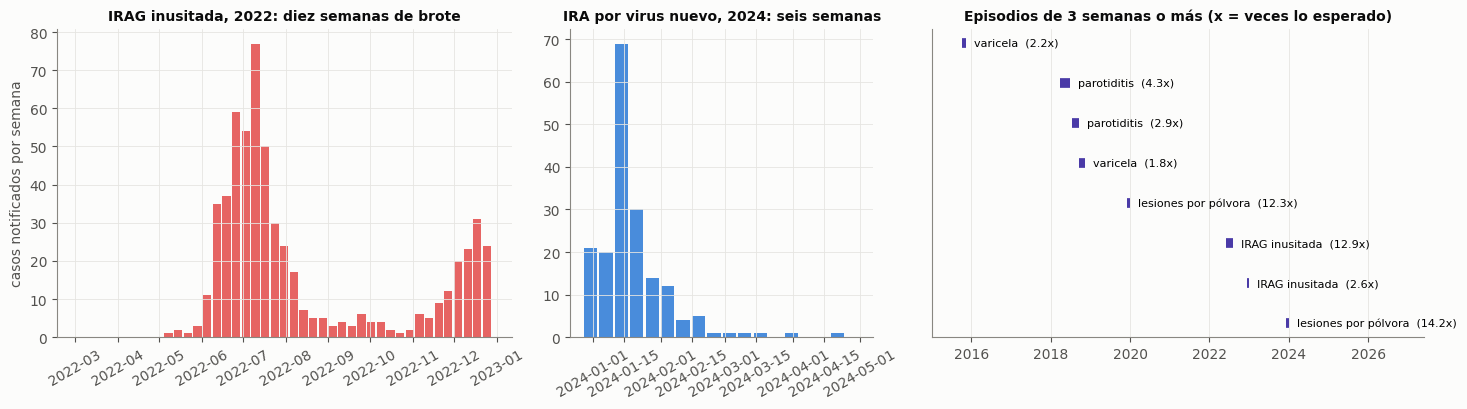

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.2, .8, 1.3]})
ax = axes[0]; x1 = P[348].loc["2022-03":"2022-12"]; ax.bar(x1.index, x1.values, width=6, color=ROJO, alpha=.85)
ax.set_ylabel("casos notificados por semana"); ax.set_title("IRAG inusitada, 2022: diez semanas de brote", fontsize=10)
ax = axes[1]; x2 = P[346].loc["2023-12":"2024-04"]; ax.bar(x2.index, x2.values, width=6, color=AZUL, alpha=.85)
ax.set_title("IRA por virus nuevo, 2024: seis semanas", fontsize=10)
for a_ in axes[:2]: a_.tick_params(axis="x", rotation=30)
ax = axes[2]; EP3 = EPI[EPI["semanas de exceso"] >= 3].sort_values("inicio")
for i, (_, r) in enumerate(EP3.iterrows()):
    ax.plot([pd.Timestamp(r.inicio), pd.Timestamp(r.fin) + pd.Timedelta(days=6)], [i, i], lw=7, color=VIOLETA, solid_capstyle="butt")
    ax.text(pd.Timestamp(r.fin) + pd.Timedelta(days=80), i, f"{r.evento}  ({r['veces lo esperado']}x)", va="center", fontsize=8)
ax.set_yticks([]); ax.set_xlim(pd.Timestamp("2015-01-01"), pd.Timestamp("2027-06-01")); ax.invert_yaxis(); ax.set_title("Episodios de 3 semanas o más (x = veces lo esperado)", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura.** La regla encuentra 77 episodios de exceso, de los cuales 8 duran tres semanas o más. Representan tres tipos distintos de fenómeno.

- **Epidemias reales de enfermedad transmisible**: la parotiditis de 2018 (dos oleadas, de 7 y 5 semanas, con 4,3 y 2,9 veces lo esperado), las dos olas de varicela de 2015 y 2018 (2,2 y 1,8 veces) y, dentro de los años del hospital, la **IRAG inusitada de 2022**, con 12,9 veces lo esperado en 9 semanas de exceso (junio y julio) y una segunda onda más pequeña en diciembre (2,6 veces).
- **Un fenómeno estacional que la regla confunde con epidemia**: las lesiones por pólvora de diciembre (12,3 y 14,2 veces en 2019 y 2023). La regla compara con las 52 semanas anteriores, que no tienen diciembre, y por eso lo marca cada año. Es una enfermedad con calendario, no un brote.
- **Un brote sin línea de base**: la IRA por virus nuevo de 2024, que empezó a notificarse a finales de 2023 y por eso la regla no puede evaluarla. La gráfica de la izquierda lo muestra con un máximo semanal de 69 casos.

La varicela de 2015 y 2018 y la parotiditis de 2018 son anteriores a los datos de triage (desde 2020) y no se pueden cruzar con el hospital. De los episodios que sí caen en el periodo del hospital, solo hay dos de enfermedad transmisible: el de 2022 y el de 2024.

IRAG inusitada, mayo-septiembre de 2022: 434 casos, máximo semanal 77 (2022-07-10)
IRA por virus nuevo, 2023-12-31 a 2024-02-11: 170 casos, máximo semanal 69 (2024-01-14)


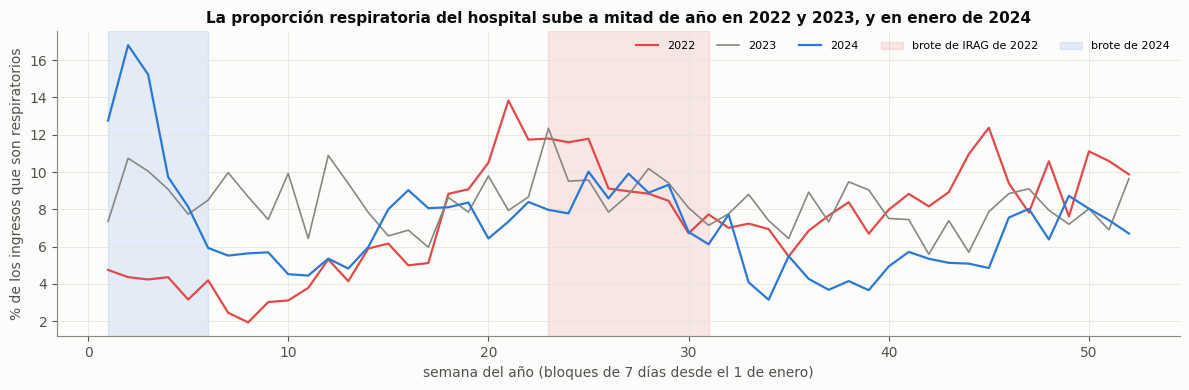

,semanas 23-31 (jun-jul),semanas 1-6 (ene-feb),resto del año
2022,9.45,4.18,7.58
2023,9.21,8.91,8.04
2024,8.38,11.43,6.11


In [21]:
x1 = P[348].loc["2022-05":"2022-09"]; x2 = P[346].loc["2023-12":"2024-02"]
print(f"IRAG inusitada, mayo-septiembre de 2022: {int(x1.sum())} casos, máximo semanal {int(x1.max())} ({x1.idxmax().date()})")
print(f"IRA por virus nuevo, 2023-12-31 a 2024-02-11: {int(x2.loc[:'2024-02-11'].sum())} casos, máximo semanal {int(x2.max())} ({x2.idxmax().date()})")
# lo que ve el hospital: proporción de ingresos del capítulo respiratorio sobre todos los capítulos, por semana del año
dxs = dx.groupby("dia").n.sum().reindex(pd.date_range("2020-01-01", FIN)).fillna(0)
rs = dx[dx.capitulo == "X Respiratorio"].set_index("dia").n.reindex(dxs.index).fillna(0)
tot_s = ix.semana(dxs, "sum"); prop = (ix.semana(rs, "sum") / tot_s * 100)[tot_s > 0]
wk = pd.Series((prop.index.dayofyear - 1) // 7 + 1, index=prop.index); yr = prop.index.year       # semana de 7 dias contada desde el 1 de enero
fig, ax = plt.subplots(figsize=(12, 4))
for a, col in [(2022, ROJO), (2023, MUDO), (2024, AZUL)]:
    sel = (yr == a) & (wk <= 52); ax.plot(wk[sel].values, prop[sel].values, color=col, lw=1.6 if a != 2023 else 1.2, label=str(a))
ax.axvspan(23, 31, color=ROJO, alpha=.12, label="brote de IRAG de 2022"); ax.axvspan(1, 6, color=AZUL, alpha=.12, label="brote de 2024")
ax.set_xlabel("semana del año (bloques de 7 días desde el 1 de enero)"); ax.set_ylabel("% de los ingresos que son respiratorios"); ax.legend(ncol=5, fontsize=8)
ax.set_title("La proporción respiratoria del hospital sube a mitad de año en 2022 y 2023, y en enero de 2024")
plt.tight_layout(); plt.show()
def media_ep(a, s_ini, s_fin):
    sel = (yr == a) & (wk >= s_ini) & (wk <= s_fin); return prop[sel].mean()
pd.DataFrame({"semanas 23-31 (jun-jul)": [media_ep(a, 23, 31) for a in (2022, 2023, 2024)],
              "semanas 1-6 (ene-feb)": [media_ep(a, 1, 6) for a in (2022, 2023, 2024)],
              "resto del año": [prop[(yr == a) & ~wk.isin(list(range(1, 7)) + list(range(23, 32)))].mean() for a in (2022, 2023, 2024)]},
             index=[2022, 2023, 2024]).round(2)

**Lectura.** El hospital no muestra un exceso respiratorio claro durante los brotes de la ciudad.

En el brote de IRAG inusitada de 2022 (434 casos notificados de mayo a septiembre, con un máximo de 77 en la semana del 10 de julio), la proporción de ingresos respiratorios de las semanas 23 a 31 fue de 9,45 %, frente a 9,21 % en 2023 y 8,38 % en 2024 en las mismas semanas. Frente al resto de su propio año (7,58 %, 8,04 % y 6,11 %) la subida de 2022 es de 1,25 veces, la de 2023 de 1,15 y la de 2024 de 1,37: la onda de mitad de año de 2022 queda dentro del rango de los otros años. Un brote que multiplicó por casi 13 lo esperado en la ciudad no se ve como una subida distinta en el hospital, y no se puede saber con estos datos si fue porque los casos no consultaron a este servicio o porque se mezclan con la onda estacional habitual.

En enero y febrero de 2024, durante la IRA por virus nuevo (170 casos de la semana 2023-12-31 a la del 11 de febrero, con un máximo de 69 en la semana del 14 de enero), la proporción respiratoria llega a 11,43 %, la más alta de las tres comparaciones (8,91 % en 2023 y 4,18 % en 2022) y 1,87 veces el resto de 2024. Es consistente con una respuesta del hospital, pero es un solo episodio, el de 2023 también estuvo alto en esas semanas, y no se puede separar de la estación. El valor bajo de 2022 en enero y febrero es probablemente una consecuencia de que los diagnósticos de COVID-19 se agrupan en otro capítulo del catálogo; este análisis no lo comprueba.

La proporción tiene el denominador de todos los ingresos del hospital por capítulo, de modo que no refleja el ciclo del volumen total.

---
# 7. Conclusiones y límites

**Lo que muestra este cuaderno:**

1. **Seis familias de enfermedad de la ciudad** reemplazan a la IRA sola como repertorio. Cinco tienen dato de 2026 al predecir; la digestiva no, porque solo llega con los microdatos, con unos ocho meses de retraso.
2. **Las familias son casi independientes** (ninguna correlación semanal supera 0,19) y tienen estaciones propias, aunque tres coinciden en agosto.
3. **El clima mueve a las enfermedades transmisibles de la ciudad.** Tras una racha seca la respiratoria baja hasta −9,5 %; cuanto más pasa desde una semana muy lluviosa, la digestiva sube +15,7 % y la varicela hasta +23,6 %. No mueve a las violencias, la salud mental ni lo materno-perinatal.
4. **Al triage total llega poco.** De 30 pruebas sobreviven 4, con efectos de 1 a 3 %. La dilución se ve mejor por edad: la familia respiratoria sube el triage de los niños de 0 a 4 años un +8,7 %, pero esa banda es el 3,1 % del volumen. Los adultos de 15 a 64 años son los que llevan los resultados del total. En los mayores de 65, una comparación emparejada con la IRA de 60 o más (+2,9 %, q = 0,080) queda apenas bajo el umbral: es una pista, no una confirmación.
5. **Los episodios no sostienen los hallazgos aparentes.** La varicela durante el paro nacional (+0,67) cae dentro de lo que el azar produce y los conteos crudos bajan; la salud mental con los desastres (+0,36) descansa en la alerta del volcán de 2023. Y el brote de IRAG inusitada de 2022, el más grande de los de la ciudad (12,9 veces lo esperado), no se distingue en la proporción respiratoria del hospital de la onda de mitad de año de los otros años. Ninguno se toma como hallazgo.

**Límites del análisis.**
- La familia digestiva no tiene datos de 2026; sirve para explicar, no para operar.
- Todo se mide con datos hasta 2024. Lo hallado en la sección 5 con las bandas de edad no se ha medido fuera de muestra, y las bandas de la vigilancia (60 o más) no coinciden con las del hospital (65 o más).
- Las pruebas por banda de edad son 150 en total y la corrección se aplicó dentro de cada banda.
- Los episodios son pocos: un paro, tres desastres confirmados (dos con un solo día), dos brotes respiratorios en el periodo del hospital. Con tan pocos casos, un efecto real de pocas semanas no se distingue de la tendencia, y la ausencia de efecto no queda demostrada.
- «No se puede separar de la fecha» es la conclusión honesta para el paro y la alerta del volcán: se parecen a otros fenómenos que ocurrieron a la vez (la reapertura escolar, la crisis de la red).

La arquitectura que se desprende de los cuadernos 17, 18 y 19:

| Capa | Qué mueve |
|---|---|
| Clima | Las familias transmisibles de la ciudad |
| Familias | Su parte del triage, sobre todo la de los niños y los adultos |
| Red de salud | El nivel del total |
| Calendario | El día a día |

Es lo que prueba el cuaderno 21 con el modelo jerárquico por tipo de consulta.